# Seed to voxel (whole-brain) functional connectivity

## Initialization, paths, settings..

In [1]:
%matplotlib inline

from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import json
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from nilearn import image, plotting
from nilearn.maskers import NiftiLabelsMasker, NiftiMasker

sns.set_context('notebook')
sns.set_style('whitegrid')


In [2]:
BIDS_DIR = Path.cwd()
DERIV_DIR = BIDS_DIR / 'fmriprep-reconed'

SUBJECT = 'sub-MM030926'
SESSION = 'ses-01'
TASK = 'task-rest'
SPACE = 'MNI152NLin2009cAsym'

BOLD_PATH = Path(f'{DERIV_DIR}/{SUBJECT}/{SESSION}/func/{SUBJECT}_{SESSION}_{TASK}_space-{SPACE}_desc-preproc_bold.nii.gz')
CONFOUNDS_PATH = Path(f'{DERIV_DIR}/{SUBJECT}/{SESSION}/func/{SUBJECT}_{SESSION}_{TASK}_desc-confounds_timeseries.tsv')
BRAIN_MASK_PATH = BOLD_PATH.with_name(BOLD_PATH.name.replace("desc-preproc_bold", "desc-brain_mask"))

OUTPUT_DIR = Path.cwd() / 'seed_to_voxel'
OUTPUT_DIR.mkdir(exist_ok=True)
CORRELATION_MAP_PATH = OUTPUT_DIR / f'{SUBJECT}_{SESSION}_{TASK}_space-{SPACE}_desc-bilateralAmygdala_seedCorrelation.nii.gz'
FISHER_Z_MAP_PATH = OUTPUT_DIR / f'{SUBJECT}_{SESSION}_{TASK}_space-{SPACE}_desc-bilateralAmygdala_seedCorrelationFisherZ.nii.gz'

In [3]:
FWHM = 6
LOW_PASS = 0.10
HIGH_PASS = 0.01

INCLUDE_GLOBAL_SIGNAL = False

with open(BOLD_PATH.with_suffix('').with_suffix('.json')) as f:
    bold_meta = json.load(f)
TR = float(bold_meta.get('RepetitionTime', nib.load(str(BOLD_PATH)).header.get_zooms()[3]))

In [4]:
bold_img = nib.load(str(BOLD_PATH))
#brain_mask_img = nib.load(str(BRAIN_MASK_PATH))
#mean_bold = image.mean_img(str(BOLD_PATH))

## Seed mask

In [5]:
ASEG_MNI = OUTPUT_DIR / "aseg_in_mni.nii.gz"

!wget -O "{ASEG_MNI}" "https://templateflow.s3.amazonaws.com/tpl-MNI152NLin2009cAsym/tpl-MNI152NLin2009cAsym_res-01_seg-aseg_dseg.nii.gz"

--2026-11-09 10:45:14--  https://templateflow.s3.amazonaws.com/tpl-MNI152NLin2009cAsym/tpl-MNI152NLin2009cAsym_res-01_seg-aseg_dseg.nii.gz
wget: /home/jovyan/.netrc:2: unknown token "user"
wget: /home/jovyan/.netrc:2: unknown token "88d10aed-5c3a-4b3f-a22c-b7329e325bdf"
Resolving templateflow.s3.amazonaws.com (templateflow.s3.amazonaws.com)... 52.217.141.90, 16.15.252.178, 16.15.229.93, ...
Connecting to templateflow.s3.amazonaws.com (templateflow.s3.amazonaws.com)|52.217.141.90|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 484957 (474K) [application/gzip]
Saving to: ‘/home/jovyan/shared_storage/RESTING-STATE/seed_to_voxel/aseg_in_mni.nii.gz’

/home/jovyan/shared 100%[===================>] 473.59K  1.00MB/s    in 0.5s    

2026-11-09 10:45:15 (1.00 MB/s) - ‘/home/jovyan/shared_storage/RESTING-STATE/seed_to_voxel/aseg_in_mni.nii.gz’ saved [484957/484957]



In [6]:
import os
from nipype.interfaces import fsl

os.environ["FSLDIR"] = "/home/jovyan/shared_storage/fsl/share/fsl"
os.environ["PATH"] = f'{os.environ["FSLDIR"]}/bin:' + os.environ["PATH"]
os.environ["FSLOUTPUTTYPE"]="NIFTI_GZ"

ASEG_IN_FUNC = OUTPUT_DIR / "aseg_in_func.nii.gz"

flt = fsl.FLIRT(
    in_file=str(ASEG_MNI),
    reference=str(BRAIN_MASK_PATH),
    out_file=str(ASEG_IN_FUNC),
    apply_xfm=True,
    uses_qform=True,
    interp="nearestneighbour",
)

res = flt.run()

In [7]:
import numpy as np
from nilearn.image import new_img_like

aseg_img = nib.load(ASEG_IN_FUNC)
aseg = np.asarray(aseg_img.dataobj)

amygdala_mask = np.isin(aseg, [18, 54]).astype(np.uint8)

amygdala_img = new_img_like(
    aseg_img,
    amygdala_mask,
    copy_header=True,
)

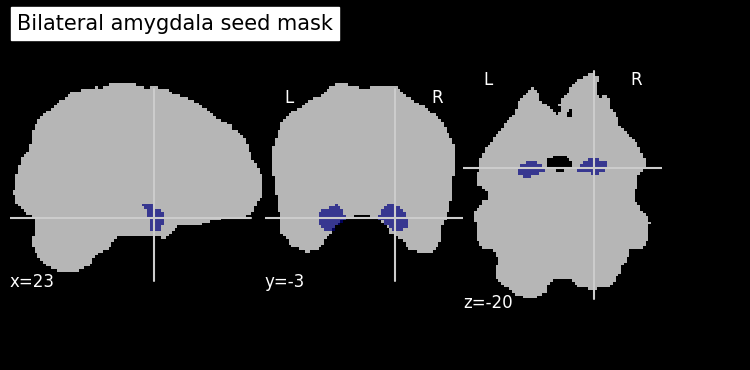

In [8]:
seed_coords = plotting.find_xyz_cut_coords(amygdala_img)

plotting.plot_roi(
    amygdala_img,
    bg_img=str(BRAIN_MASK_PATH),
    title='Bilateral amygdala seed mask',
    display_mode='ortho',
    cut_coords=seed_coords,
)
plt.show()

## Confound list

In [9]:
confound_columns = [
    # Motion: 24 parameters
    "trans_x", "trans_x_derivative1", "trans_x_power2", "trans_x_derivative1_power2",
    "trans_y", "trans_y_derivative1", "trans_y_power2", "trans_y_derivative1_power2",
    "trans_z", "trans_z_derivative1", "trans_z_power2", "trans_z_derivative1_power2",
    "rot_x", "rot_x_derivative1", "rot_x_power2", "rot_x_derivative1_power2",
    "rot_y", "rot_y_derivative1", "rot_y_power2", "rot_y_derivative1_power2",
    "rot_z", "rot_z_derivative1", "rot_z_power2", "rot_z_derivative1_power2",

    # CSF + WM
    "csf", "csf_derivative1", "csf_power2", "csf_derivative1_power2",
    "white_matter", "white_matter_derivative1",
    "white_matter_power2", "white_matter_derivative1_power2",
]

confounds = pd.read_csv(CONFOUNDS_PATH, sep="\t")[confound_columns]

confounds = confounds.replace([np.inf, -np.inf], np.nan).fillna(0)

#confounds = (
#    (confounds - confounds.mean())
#    / confounds.std(ddof=0).replace(0, np.nan)
#).fillna(0)

## Extract timeseries

## TUTAJ REGRESJA I FILTRACJA SĄ W JEDNYM KROKU (CONN RunBP Simultanous)

```
masker_kwargs = dict(
    detrend=True,
    standardize_confounds=True,
    standardize='zscore_sample',
    low_pass=LOW_PASS,
    high_pass=HIGH_PASS,
    t_r=TR,
    memory=str(OUTPUT_DIR / 'nilearn_cache'),
    memory_level=1,
    verbose=1,
)

seed_masker = NiftiLabelsMasker(
    labels_img=amygdala_img,
    background_label=0,
    **masker_kwargs,
)
seed_time_series = seed_masker.fit_transform(
    str(BOLD_PATH),
    confounds=confounds,
)

brain_masker = NiftiMasker(
    mask_img=str(BRAIN_MASK_PATH),
    smoothing_fwhm=FWHM,
    **masker_kwargs,
)
brain_time_series = brain_masker.fit_transform(
    str(BOLD_PATH),
    confounds=confounds,
)


print(f'Seed time series shape: {seed_time_series.shape}')
print(f'Brain time series shape: {brain_time_series.shape}')
#print(f'Seed time series saved to: {SEED_TIMESERIES_PATH}')
```

In [10]:
## Regresja najpierw, filtracja później (CONN RegBP After (default)

from nilearn.signal import clean

# Etap 1: usunięcie trendu i regresja confoundów, bez filtracji.
masker_kwargs = dict(
    detrend=True,
    standardize_confounds=True,
    standardize=None,
    low_pass=None,
    high_pass=None,
    t_r=TR,
    memory=str(OUTPUT_DIR / 'nilearn_cache'),
    memory_level=1,
    verbose=1,
)

seed_masker = NiftiLabelsMasker(
    labels_img=amygdala_img,
    background_label=0,
    **masker_kwargs,
)
seed_time_series = seed_masker.fit_transform(
    str(BOLD_PATH),
    confounds=confounds,
)

brain_masker = NiftiMasker(
    mask_img=str(BRAIN_MASK_PATH),
    smoothing_fwhm=FWHM,
    **masker_kwargs,
)
brain_time_series = brain_masker.fit_transform(
    str(BOLD_PATH),
    confounds=confounds,
)

# Etap 2: filtracja po regresji (After), następnie standaryzacja.
filter_kwargs = dict(
    detrend=False,
    confounds=None,  # bez ponownej regresji
    filter='butterworth',
    low_pass=LOW_PASS,
    high_pass=HIGH_PASS,
    t_r=TR,
    standardize='zscore_sample',
)

seed_time_series = clean(seed_time_series, **filter_kwargs)
brain_time_series = clean(brain_time_series, **filter_kwargs)


print(f'Seed time series shape: {seed_time_series.shape}')
print(f'Brain time series shape: {brain_time_series.shape}')

[NiftiLabelsMasker.wrapped] Loading data from sub-MM030926_ses-0...
[NiftiLabelsMasker.wrapped] Loading regions from <nibabel.nifti1.Nifti1Image object at 0x7f1a904d8770>
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiMasker.wrapped] Loading data from sub-MM030926_ses-0...
[NiftiMasker.wrapped] Loading mask from sub-MM030926_ses-0...
[NiftiMasker.wrapped] Resampling mask
[NiftiMasker.wrapped] Finished fit
Seed time series shape: (520, 1)
Brain time series shape: (520, 224605)


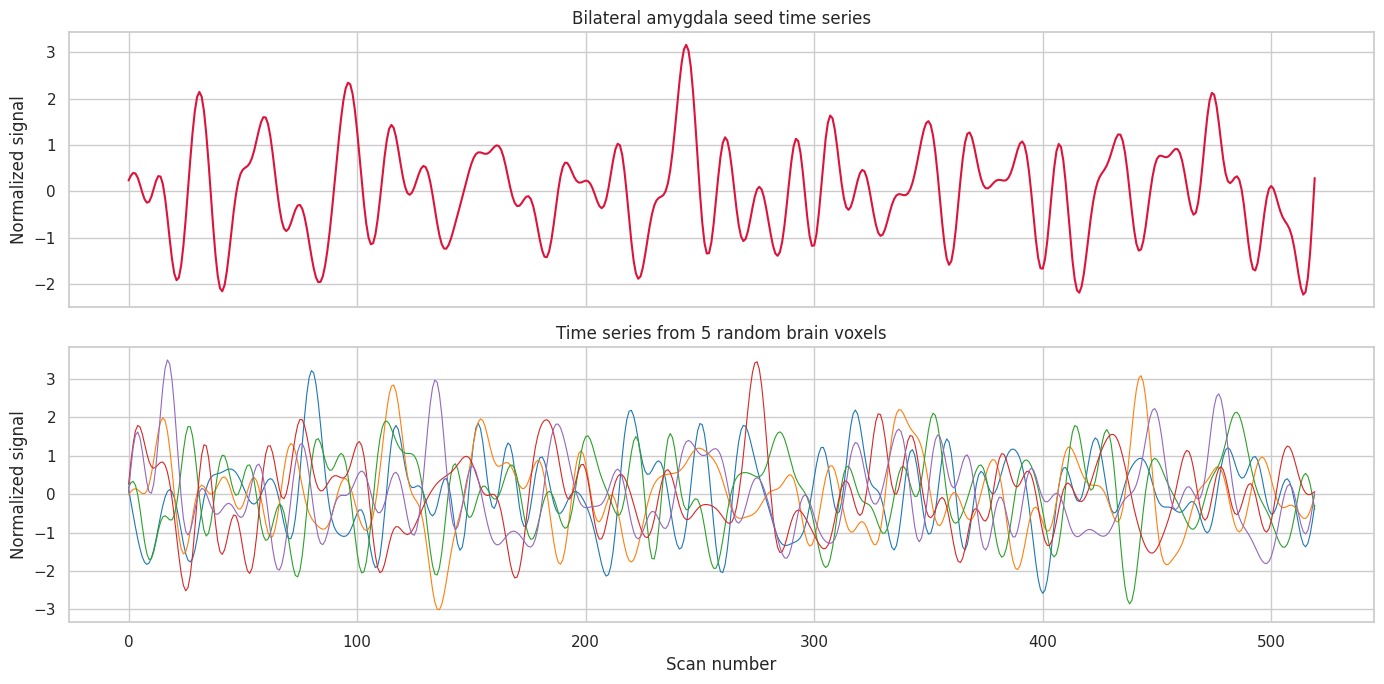

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(seed_time_series[:, 0], color='crimson', linewidth=1.5)
axes[0].set_title('Bilateral amygdala seed time series')
axes[0].set_ylabel('Normalized signal')

rng = np.random.default_rng(42)
voxel_indices = rng.choice(brain_time_series.shape[1], size=min(5, brain_time_series.shape[1]), replace=False)
axes[1].plot(brain_time_series[:, voxel_indices], linewidth=0.8)
axes[1].set_title('Time series from 5 random brain voxels')
axes[1].set_xlabel('Scan number')
axes[1].set_ylabel('Normalized signal')
plt.tight_layout()
plt.show()

## Compute correlations

Seed-to-voxel correlation shape: (224605, 1)
Seed-to-voxel correlation: min = -0.535; max = 0.729; mean = 0.109


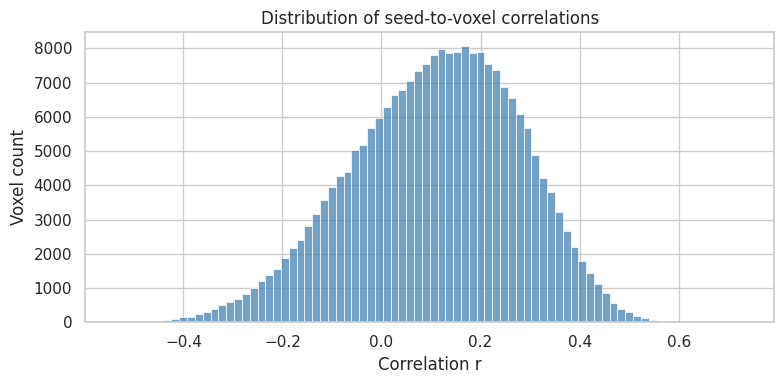

In [12]:
seed_to_voxel_correlations = np.dot(brain_time_series.T, seed_time_series) / (seed_time_series.shape[0] - 1) #N-1 as both signals are zscored
seed_to_voxel_correlations = np.clip(seed_to_voxel_correlations, -0.999999, 0.999999)

print(f'Seed-to-voxel correlation shape: {seed_to_voxel_correlations.shape}')
print(
    'Seed-to-voxel correlation: '
    f'min = {seed_to_voxel_correlations.min():.3f}; '
    f'max = {seed_to_voxel_correlations.max():.3f}; '
    f'mean = {seed_to_voxel_correlations.mean():.3f}'
)

plt.figure(figsize=(8, 4))
sns.histplot(seed_to_voxel_correlations.ravel(), bins=80, color='steelblue')
plt.title('Distribution of seed-to-voxel correlations')
plt.xlabel('Correlation r')
plt.ylabel('Voxel count')
plt.tight_layout()
plt.show()

[NiftiMasker.inverse_transform] Computing image from signals
[NiftiMasker.inverse_transform] Computing image from signals


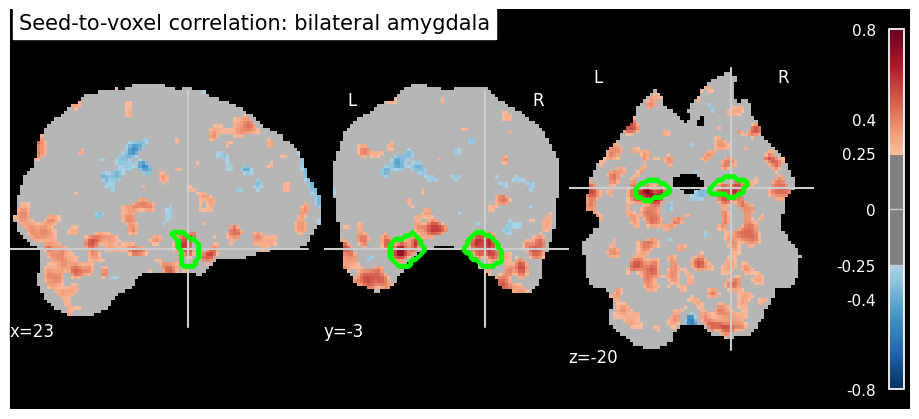

In [13]:
seed_to_voxel_correlations_img_4d = brain_masker.inverse_transform(seed_to_voxel_correlations.T)
seed_to_voxel_correlations_img = image.index_img(seed_to_voxel_correlations_img_4d, 0)
seed_to_voxel_correlations_img.to_filename(str(CORRELATION_MAP_PATH))

seed_to_voxel_correlations_fisher_z = np.arctanh(seed_to_voxel_correlations)
seed_to_voxel_correlations_fisher_z_img_4d = brain_masker.inverse_transform(seed_to_voxel_correlations_fisher_z.T)
seed_to_voxel_correlations_fisher_z_img = image.index_img(seed_to_voxel_correlations_fisher_z_img_4d, 0)
seed_to_voxel_correlations_fisher_z_img.to_filename(str(FISHER_Z_MAP_PATH))

CORRELATION_THRESHOLD = 0.25
VMAX = 0.80 # colorbar -VMAX ───── 0 ───── +VMAX

fig = plt.figure(figsize=(9, 4))
display_map = plotting.plot_stat_map(
    seed_to_voxel_correlations_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=CORRELATION_THRESHOLD,
    vmax=VMAX,
    cut_coords=seed_coords,
    title='Seed-to-voxel correlation: bilateral amygdala',
    display_mode='ortho',
    colorbar=True,
    figure=fig,
)
display_map.add_contours(amygdala_img, colors='lime', linewidths=1.5)
plt.show()

## Connectivity by GLM instead of correlations

In this example I decided to use non-filtered seed timeseries (raw). It is different as compared to correlations on filtered signals.

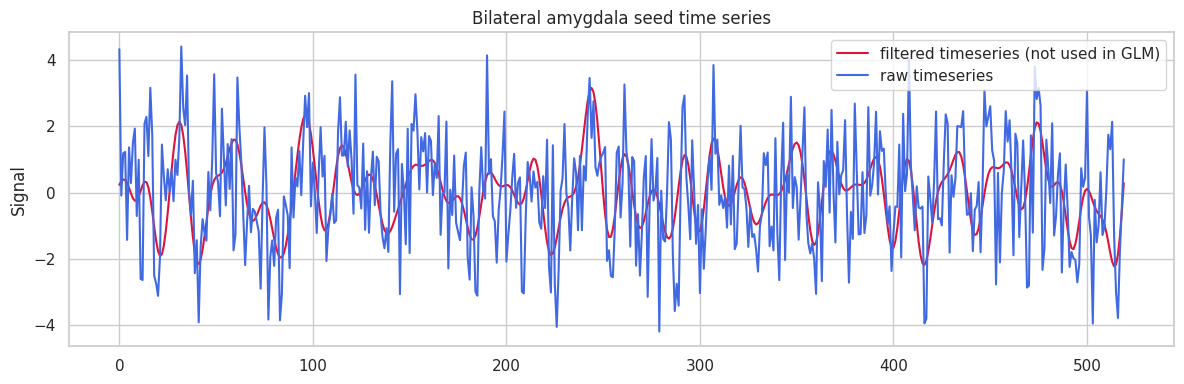

In [25]:

#masker_kwargs = dict(
#    detrend=True,
#    standardize_confounds=True,
#    standardize='zscore_sample',
#    low_pass=LOW_PASS,
#    high_pass=HIGH_PASS,
#    t_r=TR,
#    memory=str(OUTPUT_DIR / 'nilearn_cache'),
#    memory_level=1,
#    verbose=1,
#)
seed_masker_raw = NiftiLabelsMasker(
    labels_img=amygdala_img,
    background_label=0,
    standardize=None
)
seed_time_series_raw = seed_masker_raw.fit_transform(
    str(BOLD_PATH),
    confounds = None
)
seed_time_series_raw = seed_time_series_raw - seed_time_series_raw.mean()

plt.figure(figsize=(12, 4))
plt.plot(seed_time_series[:, 0], color='crimson', linewidth=1.5, label='filtered timeseries (not used in GLM)')
plt.plot(seed_time_series_raw[:, 0], color='royalblue', linewidth=1.5, label='raw timeseries')
plt.title('Bilateral amygdala seed time series')
plt.ylabel('Signal')
plt.tight_layout()
plt.legend()
plt.show()

In [26]:
# all brain voxels are smoothed with the same kernel as for correlations

brain_masker = NiftiMasker(
    mask_img=str(BRAIN_MASK_PATH),
    smoothing_fwhm=FWHM,
    **masker_kwargs,
)
brain_time_series = brain_masker.fit_transform(
    str(BOLD_PATH),
    confounds=confounds,
)

[NiftiMasker.wrapped] Loading data from sub-MM030926_ses-0...
[NiftiMasker.wrapped] Loading mask from sub-MM030926_ses-0...
[NiftiMasker.wrapped] Resampling mask
[NiftiMasker.wrapped] Finished fit


In [27]:
#i used the same confounds but filtering in GLM is quite different - high pass 0.01 but no low pass available

import numpy as np
import pandas as pd
from scipy.stats import zscore

from nilearn.glm.first_level import make_first_level_design_matrix

n_trs = len(seed_time_series)
frame_times = np.arange(n_trs) * TR

seed = np.asarray(seed_time_series_raw).squeeze()

regressors = confounds.copy()
regressors["amygdala"] = seed

#z-score seed and confounds but not outliers
continuous_cols = [
    c for c in regressors.columns
    if not c.startswith("motion_outlier")
    and not c.startswith("non_steady_state_outlier")
]
regressors[continuous_cols] = zscore(
    regressors[continuous_cols],
    axis=0,
    ddof=1,
    nan_policy="omit",
)

design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    hrf_model=None,
    drift_model="cosine",
    high_pass=0.01,
    add_regs=regressors.to_numpy(),
    add_reg_names=regressors.columns.tolist(),
)

display(design_matrix.head())
print(design_matrix.shape)

,trans_x,trans_x_derivative1,trans_x_power2,trans_x_derivative1_power2,trans_y,trans_y_derivative1,trans_y_power2,trans_y_derivative1_power2,trans_z,trans_z_derivative1,...,amygdala,drift_1,drift_2,drift_3,drift_4,drift_5,drift_6,drift_7,drift_8,constant
0.0,-0.331967,-0.014220,-0.637256,-0.310392,-0.026770,0.001703,-0.535904,-0.831610,3.038333,0.008434,...,2.599474,0.062017,0.062016,0.062015,0.062013,0.062010,0.062007,0.062004,0.061999,1.0
0.8,-0.426864,-0.438383,-0.702084,-0.254451,1.905558,2.005453,-0.080173,2.513743,3.160889,0.282464,...,-0.055350,0.062015,0.062007,0.061994,0.061977,0.061954,0.061926,0.061893,0.061854,1.0
1.6,-0.406163,0.078307,-0.688496,-0.307730,0.218609,-1.747599,-0.709506,1.718059,3.069233,-0.196504,...,0.712779,0.062010,0.061989,0.061954,0.061904,0.061841,0.061763,0.061671,0.061565,1.0
2.4,-0.594284,-0.855070,-0.800639,-0.090558,-0.369435,-0.608077,-0.180797,-0.521797,3.078033,0.028111,...,0.736307,0.062004,0.061962,0.061893,0.061796,0.061671,0.061519,0.061339,0.061132,1.0
3.2,-0.679811,-0.396503,-0.843195,-0.264953,-1.142675,-0.800118,1.103025,-0.295926,3.340825,0.596026,...,-0.859147,0.061994,0.061926,0.061811,0.061651,0.061445,0.061194,0.060898,0.060556,1.0


(520, 42)


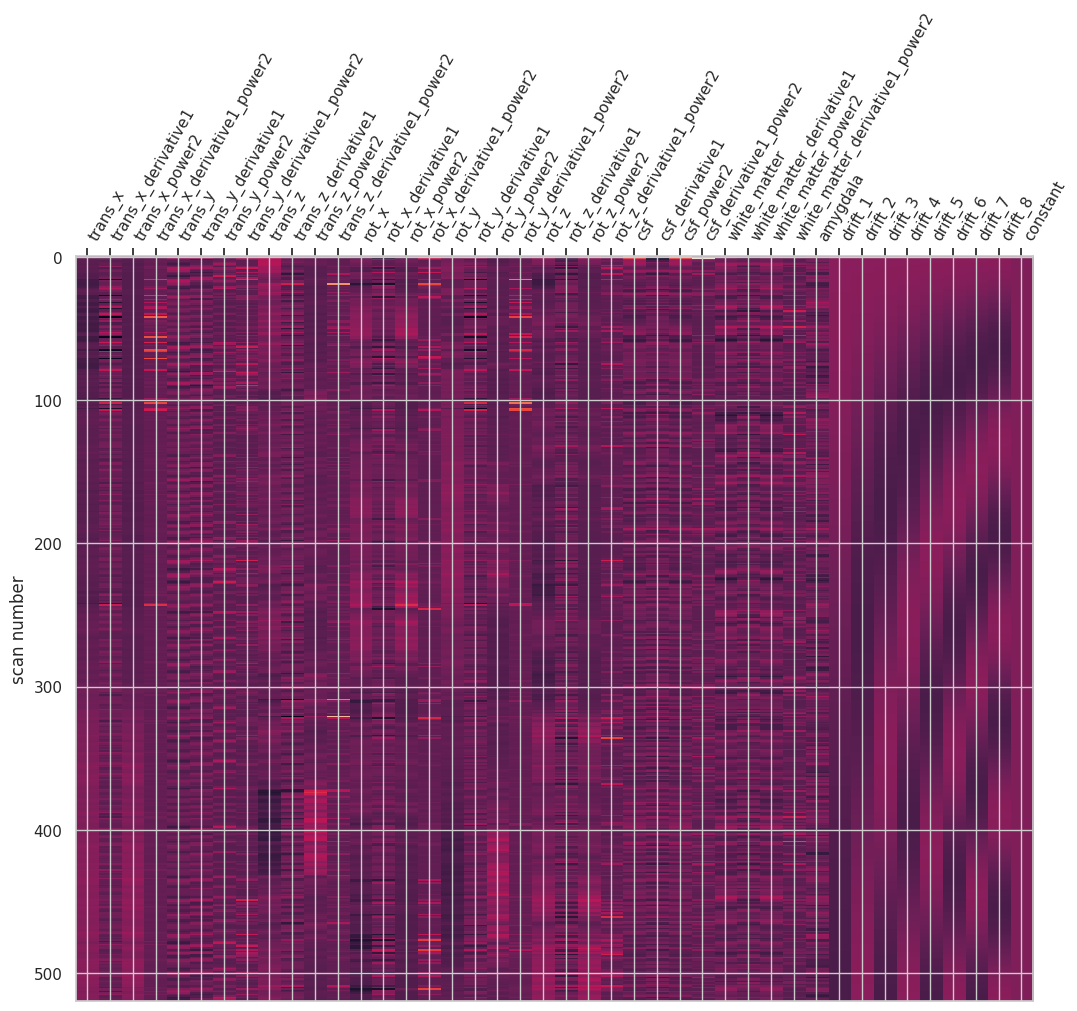

In [17]:
from nilearn.plotting import plot_design_matrix
import matplotlib.pyplot as plt

plot_design_matrix(design_matrix)
plt.show()

## The difference between GLM and correlations

There are some differences methodological differences between GLM and correlation method. I leave it here for educational purposes. CPAC, CONN etc thay all use correlation method though.

It is not obligatory to zscore all brain voxel before estimating GLM BUT without this it may happen that some voxels may have unusualy high betas. To compare GLM with correlations one needs to standarize all voxels as well. It is not simple as I seems not to work with FirstLevelModel(standardize="zscore_sample"). One needs to use NiftiMasker and process the data before GLM as follows...

### this does not standardize the data - first try

```
from nilearn.glm.first_level import FirstLevelModel

fmri_glm = FirstLevelModel(
    mask_img=BRAIN_MASK_PATH,
    smoothing_fwhm=6,
    noise_model="ols", #ar1 is more robust but less similar to correlations
    signal_scaling=False,
    standardize="zscore_sample" #seems not to work at all
)


fmri_glm.fit(
    BOLD_PATH,
    design_matrices=design_matrix
)

beta_img = fmri_glm.compute_contrast(
    "amygdala",
    output_type="effect_size"
)

beta_img.to_filename(OUTPUT_DIR / f'{SUBJECT}_{SESSION}_{TASK}_space-{SPACE}_desc-bilateralAmygdala_seedBetaOLS.nii.gz')

print(fmri_glm.get_params()["standardize"])

fig = plt.figure(figsize=(9, 4))
display_map = plotting.plot_stat_map(
    beta_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=0,
    #vmax=VMAX,
    cut_coords=seed_coords,
    title='Seed-to-voxel GLM: bilateral amygdala',
    display_mode='ortho',
    colorbar=True,
    figure=fig,
)
display_map.add_contours(amygdala_img, colors='lime', linewidths=1.5)
plt.show()
```

### this code does not standardize the data too

```
from nilearn.maskers import NiftiMasker

brain_masker = NiftiMasker(
    mask_img=BRAIN_MASK_PATH,
    smoothing_fwhm=6,
    standardize="zscore_sample", #will not work as expected with FirstLevelModel - see below
)
brain_masker.fit()


fmri_glm = FirstLevelModel(
    mask_img=brain_masker, #sets standardize=None again!!!
    noise_model="ols",
    signal_scaling=False,
)

fmri_glm.fit(
    BOLD_PATH,
    design_matrices=design_matrix,
)

print(brain_masker.get_params()["standardize"])
print(fmri_glm.get_params()["standardize"])
```

/tmp/ipykernel_1382021/2136200154.py:25: RuntimeWarning: [MultiNiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  fmri_glm.fit(


zscore_sample
False


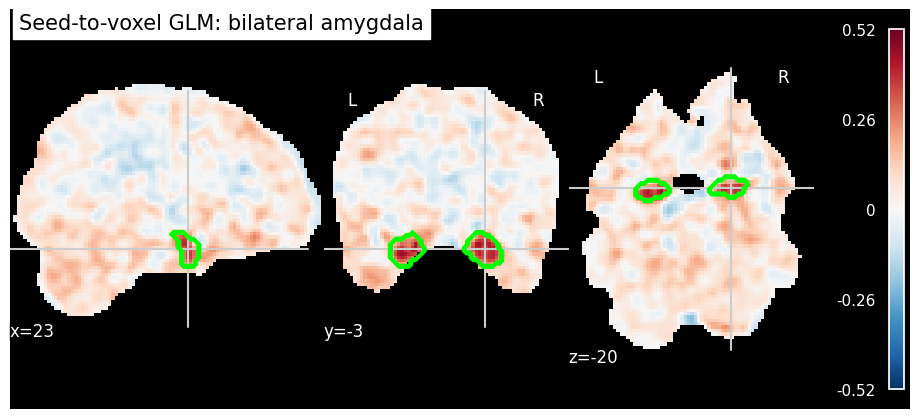

In [19]:
# this WILL standardize the data finally

from nilearn.glm.first_level import FirstLevelModel

brain_masker = NiftiMasker(
    mask_img=BRAIN_MASK_PATH,
    smoothing_fwhm=6,
    standardize="zscore_sample",
)

# time x voxels
Y_z = brain_masker.fit_transform(BOLD_PATH)

# back to 4D NIfTI
BOLD_z = brain_masker.inverse_transform(Y_z)

fmri_glm = FirstLevelModel(
    mask_img=BRAIN_MASK_PATH,
    smoothing_fwhm=None,   # smoothing already done above
    standardize=False,     # already standardized above
    noise_model="ols",
    signal_scaling=False,
)

fmri_glm.fit(
    BOLD_z,
    design_matrices=design_matrix,
)

print(brain_masker.get_params()["standardize"])
print(fmri_glm.get_params()["standardize"])

beta_img = fmri_glm.compute_contrast(
    "amygdala",
    output_type="effect_size"
)
beta_img.to_filename(OUTPUT_DIR / f'{SUBJECT}_{SESSION}_{TASK}_space-{SPACE}_desc-bilateralAmygdala_seedBetaOLS_zscored_data.nii.gz')

fig = plt.figure(figsize=(9, 4))
display_map = plotting.plot_stat_map(
    beta_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=0,
    #vmax=VMAX,
    cut_coords=seed_coords,
    title='Seed-to-voxel GLM: bilateral amygdala',
    display_mode='ortho',
    colorbar=True,
    figure=fig,
)
display_map.add_contours(amygdala_img, colors='lime', linewidths=1.5)
plt.show()

Threshold: 3.2905267314918945


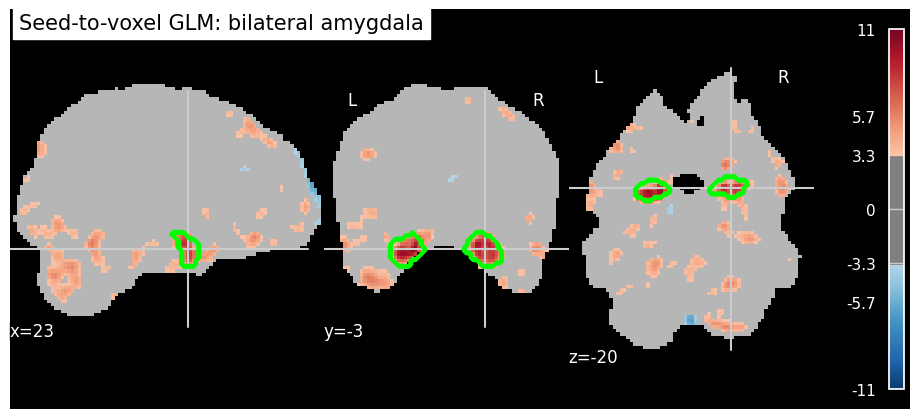

In [20]:
from nilearn.glm import threshold_stats_img
from nilearn import plotting

maps = fmri_glm.compute_contrast(
    "amygdala",
    output_type="all",
)

beta_img = maps["effect_size"]
t_img = maps["stat"]
z_img = maps["z_score"]
p_img = maps["p_value"]

thresholded_map, threshold = threshold_stats_img(
    z_img,
    alpha=0.001,
    height_control="fpr",
    cluster_threshold=10,
    two_sided=True,
)

print("Threshold:", threshold)

fig = plt.figure(figsize=(9, 4))
display_map = plotting.plot_stat_map(
    thresholded_map,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=threshold,
    #vmax=VMAX,
    cut_coords=seed_coords,
    title='Seed-to-voxel GLM: bilateral amygdala',
    display_mode='ortho',
    colorbar=True,
    figure=fig,
)
display_map.add_contours(amygdala_img, colors='lime', linewidths=1.5)
plt.show()

/tmp/ipykernel_1382021/1128042751.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


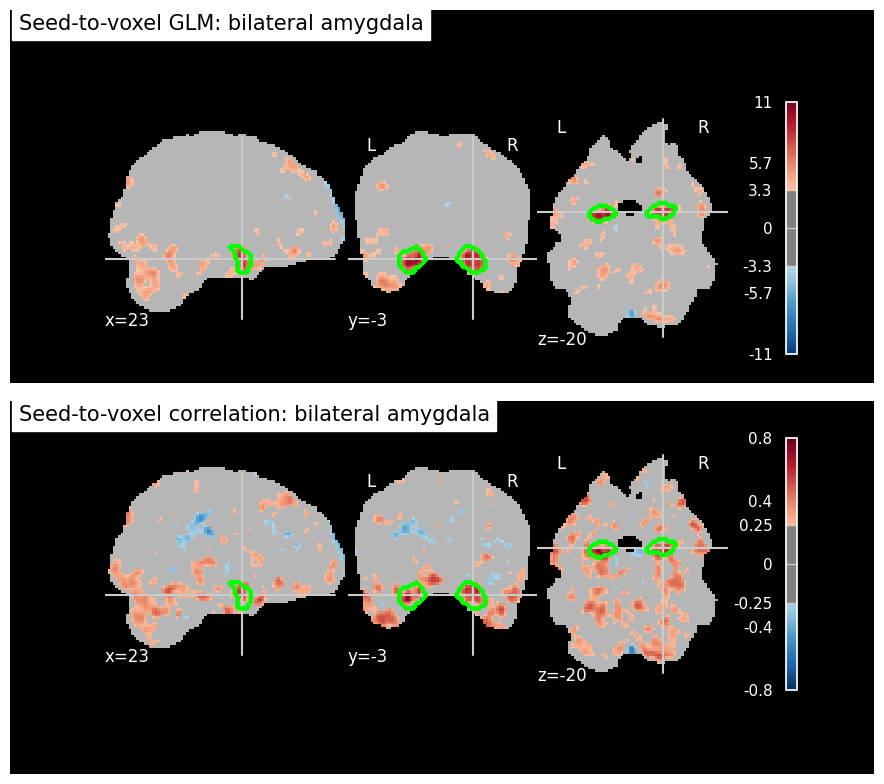

In [21]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(9, 8),
)

# --- GLM ---
display_glm = plotting.plot_stat_map(
    thresholded_map,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=threshold,
    cut_coords=seed_coords,
    title="Seed-to-voxel GLM: bilateral amygdala",
    display_mode="ortho",
    colorbar=True,
    axes=ax1,
)

display_glm.add_contours(
    amygdala_img,
    colors="lime",
    linewidths=1.5,
)


# --- Correlation ---
display_corr = plotting.plot_stat_map(
    seed_to_voxel_correlations_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=CORRELATION_THRESHOLD,
    vmax=VMAX,
    cut_coords=seed_coords,
    title="Seed-to-voxel correlation: bilateral amygdala",
    display_mode="ortho",
    colorbar=True,
    axes=ax2,
)

display_corr.add_contours(
    amygdala_img,
    colors="lime",
    linewidths=1.5,
)

plt.tight_layout()
plt.show()

## Nilearn vs C-PAC

I run cpac on the same already preprocessed data and saved filtered brain data. Then using AFNI commands I smoothed the data and calculated the correlations with amygdala as previously. See the code below.

```
~/lobi-mri-scripts/resting-state/cpac/run_cpac.sh sub-MM030926 ../fmriprep-reconed/ ./final
~/lobi-mri-scripts/resting-state/cpac/run_seed_to_voxel.sh final/output/pipeline_cpac_fmriprep-ingress/sub-MM030926/ses-01/func/sub-MM030926_ses-01_task-rest_atlas-amygdala_desc-MeanSCA_timeseries.1D final/output/pipeline_cpac_fmriprep-ingress/sub-MM030926/ses-01/func/sub-MM030926_ses-01_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz 6
```

In [22]:
#cpac_correlations_path = Path("~/shared_storage/RESTING-STATE/cpac/output/pipeline_cpac_fmriprep-ingress/sub-MM030926/ses-01/func/sub-MM030926_ses-01_task-rest_atlas-amygdala_space-MNI152NLin2009cAsym_desc-MeanSCA_correlations.nii.gz")
cpac_correlations_path = Path("~/shared_storage/RESTING-STATE/cpac/output/pipeline_cpac_fmriprep-ingress/sub-MM030926/ses-01/func/seed_to_voxel_6mm_r.nii.gz")
cpac_ts_path = Path("~/shared_storage/RESTING-STATE/cpac/output/pipeline_cpac_fmriprep-ingress/sub-MM030926/ses-01/func/sub-MM030926_ses-01_task-rest_atlas-amygdala_desc-MeanSCA_timeseries.1D")
cpac_img = nib.load(str(cpac_correlations_path))

/tmp/ipykernel_1382021/684626515.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


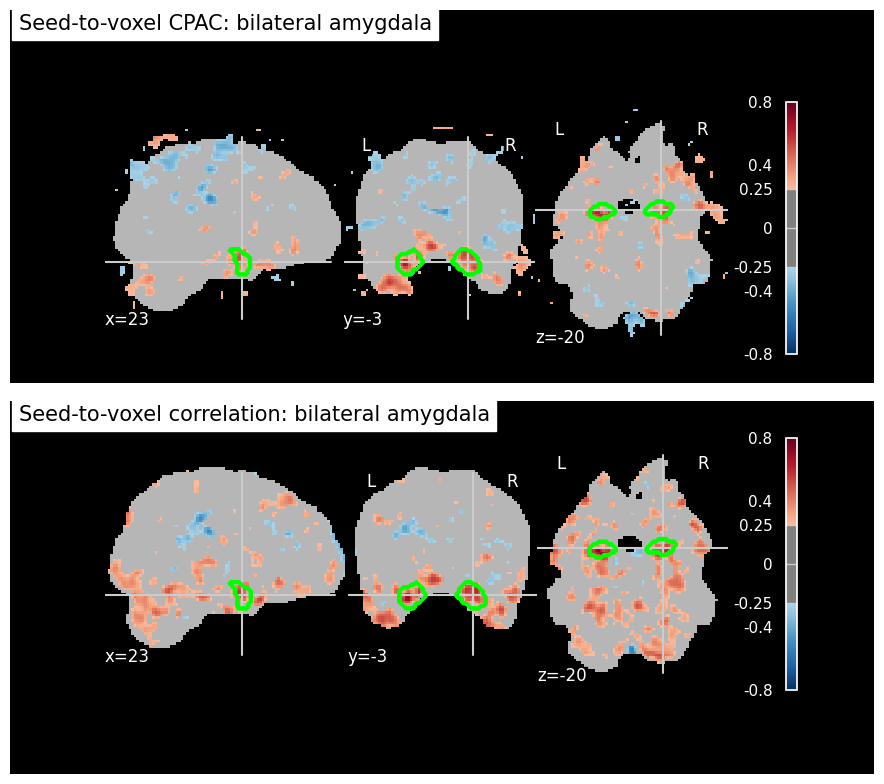

In [23]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(9, 8),
)

# --- GLM ---
display_glm = plotting.plot_stat_map(
    cpac_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=CORRELATION_THRESHOLD,
    vmax=VMAX,
    cut_coords=seed_coords,
    title="Seed-to-voxel CPAC: bilateral amygdala",
    display_mode="ortho",
    colorbar=True,
    axes=ax1,
)

display_glm.add_contours(
    amygdala_img,
    colors="lime",
    linewidths=1.5,
)


# --- Correlation ---
display_corr = plotting.plot_stat_map(
    seed_to_voxel_correlations_img,
    bg_img=str(BRAIN_MASK_PATH),
    threshold=CORRELATION_THRESHOLD,
    vmax=VMAX,
    cut_coords=seed_coords,
    title="Seed-to-voxel correlation: bilateral amygdala",
    display_mode="ortho",
    colorbar=True,
    axes=ax2,
)

display_corr.add_contours(
    amygdala_img,
    colors="lime",
    linewidths=1.5,
)

plt.tight_layout()
plt.show()

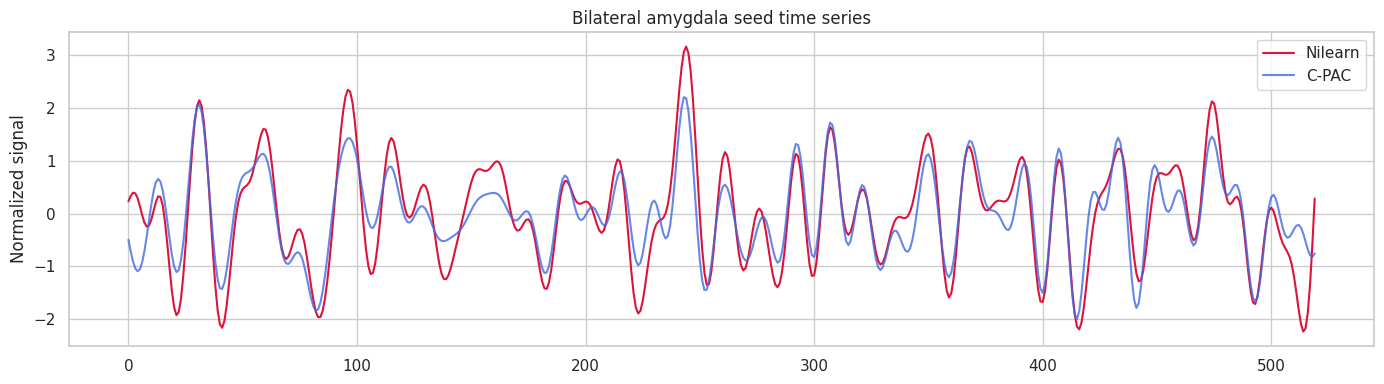

In [24]:
cpac_ts = np.loadtxt(
    cpac_ts_path.expanduser(),
    comments='#'
)

plt.figure(figsize=(14, 4))
plt.plot(seed_time_series[:, 0], color='crimson', linewidth=1.5, label='Nilearn')
plt.plot(cpac_ts, color='royalblue', linewidth=1.5, alpha=0.8, label='C-PAC')
plt.title('Bilateral amygdala seed time series')
plt.ylabel('Normalized signal')
plt.legend()

plt.tight_layout()
plt.show()